# Background

- **Author**: 第二組期中報告工作稿；個人貢獻歸屬待確認
- **Created At**: 2026-11-09
- **Research Motivation and Context (why are we interested in the findings?)：** 為期中報告重現移除月份的夜間事故分群，檢查群數、權重敏感度，以及各群照明、傷亡與行政區組成。輸入為 [正式輸入](../data/processed/taipei_2025_nighttime_clustering_input.csv)、[一般矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv)、[區塊加權矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv)及[敘述統計資料](../data/processed/taipei_2025_descriptive.csv)；定義見[分群資料說明](../data/processed/taipei_2025_nighttime_clustering_documentation.ipynb)。主樣本 N=6,701，一列暫作一事故。
- **Main Findings and Takeaways：** 一般矩陣移除月份後以6個主成分解釋83.97%變異。K=3跨種子與跨矩陣ARI均為1；K=5可辨識傍晚直路與交岔路等情境，但跨矩陣ARI僅0.459。凌晨型571件中照明問題12.96%，24小時死亡事故11件（1.93%）。受傷人數分布未見明顯差異（p=.300），行政區關聯V=0.089。
- **Future Direction：** 檢查不含天候、不同 PCA 門檻、K=3/4/6、速限0及固定夜間樣本；地圖與分層交叉分析需配合群組穩定性解讀。

本 Notebook 是期中報告的數字與圖表依據，不覆寫原先含月份的分析。主展示為不含月份的一般矩陣 K=5；五群為探索性細分，並非所有指標支持的最優群數。照明及傷亡不參與選群，行政區、座標及月份保留作分群後描述。

In [1]:
from pathlib import Path
import hashlib
import itertools
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.stats import chi2_contingency, kruskal, norm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score, calinski_harabasz_score, davies_bouldin_score
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
plt.rcParams.update({'font.sans-serif': ['Microsoft JhengHei', 'Microsoft YaHei', 'DejaVu Sans'],
                     'axes.unicode_minus': False, 'figure.dpi': 120})
RANDOM_STATE = 5166
SEEDS = [101, 203, 307, 409, 503, 607, 709, 811, 907, 1009]
print({'python': sys.executable, 'python_version': platform.python_version(),
       'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__})

{'python': 'C:\\Users\\user\\anaconda3\\python.exe', 'python_version': '3.13.5', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1'}


In [2]:
def find_root():
    for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (p / 'AGENTS.md').is_file() and (p / 'templates').is_dir():
            return p
    raise FileNotFoundError('請從學生專案內執行。')

ROOT = find_root()
OUT = ROOT / 'finding/assets/nighttime_midterm'
OUT.mkdir(parents=True, exist_ok=True)
BINDINGS = {
    'semantic': ('data/processed/taipei_2025_nighttime_clustering_input.csv',
                 'd409e9df103ff952214cf977dc0e0e8f3695cbd4e28879d143e312f4f2c5fc39',
                 '02869cf20f9362a6bf3d54ca2ca8e4b75dca983069d220bc527d6dbe9122b0f1'),
    'unweighted': ('data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv',
                   '179dd12b746fdd27513b70bdea0b07ac082edfc0ed331bf9f9977cf3973db98f',
                   '6a6d92299d333cce4dcc9b1f425faa28e0d8a20ba2b76dc7221ecc1d85328ab6'),
    'block_weighted': ('data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv',
                       'ba8178fdad20a67a80706a68fb9bb2f7013ae7c7b3a945904788635fecd4b6ed',
                       '88173998c8c597af0ce653e1b6764b03ed2582cdb961c3975de12079ab304e37'),
    'descriptive': ('data/processed/taipei_2025_descriptive.csv',
                    '09c8bae171a8307414aa787ce36f9d5d1f2f1c455dd619e250ac3fae41f15a60',
                    '09c8bae171a8307414aa787ce36f9d5d1f2f1c455dd619e250ac3fae41f15a60'),
}
frames = {}
input_rows = []
for key, (rel, local_sha, lf_sha) in BINDINGS.items():
    p = (ROOT / rel).resolve()
    assert p.is_relative_to((ROOT / 'data/processed').resolve()) and p.is_file()
    b = p.read_bytes()
    actual = hashlib.sha256(b).hexdigest()
    normalized = hashlib.sha256(b.replace(b'\r\n', b'\n')).hexdigest()
    # 僅接受已核對的本地位元組版本或相同內容的 LF 版本；其他版本明確停止。
    if actual not in {local_sha, lf_sha} or normalized != lf_sha:
        raise ValueError(f'輸入版本已改變：{rel}')
    frames[key] = pd.read_csv(p, encoding='utf-8-sig', low_memory=False)
    input_rows.append({'資料': key, '路徑': rel, '實際SHA256': actual, 'LF內容SHA256': normalized})

semantic = frames['semantic']
descriptive = frames['descriptive']
for key in ['semantic', 'unweighted', 'block_weighted']:
    f = frames[key]
    assert len(f) == 6701 and f.record_id.is_unique and not f.isna().any().any()
    assert f.record_id.tolist() == semantic.record_id.tolist()
assert len(descriptive) == 22762 and descriptive.record_id.is_unique
assert list(frames['unweighted'].columns) == list(frames['block_weighted'].columns)
for key in ['unweighted', 'block_weighted']:
    f = frames[key]
    assert f.shape == (6701, 50)
    assert np.isfinite(f.drop(columns='record_id').to_numpy()).all()
    assert not any('light' in c or 'fatal' in c or 'district' in c for c in f.columns)

outcomes = descriptive[['record_id', '光線', 'fatal24', '受傷人數', '2-30日死亡人數',
                        'district', '座標-X', '座標-Y', 'weather_label', 'road_form_label']].rename(
    columns={'光線': 'light_code', '受傷人數': 'injuries', '2-30日死亡人數': 'deaths_2to30',
             '座標-X': 'lon', '座標-Y': 'lat'})
analysis = semantic.merge(outcomes, on='record_id', how='left', validate='one_to_one')
assert len(analysis) == 6701 and not analysis.isna().any().any()
assert analysis.light_code.isin([5, 6, 7]).all()
assert analysis.fatal24.isin([0, 1]).all()
assert analysis.lon.between(121, 122).all() and analysis.lat.between(24, 26).all()
analysis['hour'] = pd.to_datetime(analysis.crash_datetime).dt.hour
analysis['month'] = pd.to_datetime(analysis.crash_datetime).dt.month
inputs = pd.DataFrame(input_rows)
display(inputs)
print('N=6,701；所有連結成功，模型輸入與結果欄無缺失。')
display(analysis.head(10))
inputs.to_csv(OUT / 'input_bindings.csv', index=False, encoding='utf-8-sig')

,資料,路徑,實際SHA256,LF內容SHA256
0,semantic,data/processed/taipei_2025_nighttime_clusterin...,d409e9df103ff952214cf977dc0e0e8f3695cbd4e28879...,02869cf20f9362a6bf3d54ca2ca8e4b75dca983069d220...
1,unweighted,data/processed/taipei_2025_nighttime_clusterin...,179dd12b746fdd27513b70bdea0b07ac082edfc0ed331b...,6a6d92299d333cce4dcc9b1f425faa28e0d8a20ba2b76d...
2,block_weighted,data/processed/taipei_2025_nighttime_clusterin...,ba8178fdad20a67a80706a68fb9bb2f7013ae7c7b3a945...,88173998c8c597af0ce653e1b6764b03ed2582cdb961c3...
3,descriptive,data/processed/taipei_2025_descriptive.csv,09c8bae171a8307414aa787ce36f9d5d1f2f1c455dd619...,09c8bae171a8307414aa787ce36f9d5d1f2f1c455dd619...


N=6,701；所有連結成功，模型輸入與結果欄無缺失。


,record_id,crash_datetime,speed_limit,hour_sin,hour_cos,month_sin,month_cos,weather_code,road_class_code,road_form_code,...,fatal24,injuries,deaths_2to30,district,lon,lat,weather_label,road_form_label,hour,month
0,1,2025-01-01 00:18:00,40,0.000000,1.000000e+00,0.0,1.0,8,5,14,...,0.0,1.0,0.0,中山區,121.529004,25.046603,晴,直路,0,1
1,2,2025-01-01 00:31:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,...,0.0,3.0,0.0,文山區,121.573689,24.991275,陰,直路,0,1
2,3,2025-01-01 00:35:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,5,...,0.0,1.0,0.0,中山區,121.547196,25.079842,陰,多岔路,0,1
3,4,2025-01-01 00:41:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,...,0.0,1.0,0.0,中山區,121.523305,25.068395,陰,直路,0,1
4,5,2025-01-01 00:57:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,3,...,0.0,1.0,0.0,南港區,121.583227,25.045872,陰,三岔路,0,1
5,6,2025-01-01 01:34:00,30,0.258819,9.659258e-01,0.0,1.0,7,5,3,...,0.0,3.0,0.0,信義區,121.565200,25.026933,陰,三岔路,1,1
6,7,2025-01-01 02:15:00,50,0.500000,8.660254e-01,0.0,1.0,7,5,14,...,0.0,1.0,0.0,信義區,121.557572,25.029541,陰,直路,2,1
7,8,2025-01-01 06:26:00,30,1.000000,6.123234e-17,0.0,1.0,8,5,12,...,0.0,1.0,0.0,文山區,121.597223,24.972428,晴,坡路,6,1
8,9,2025-01-01 06:29:00,50,1.000000,6.123234e-17,0.0,1.0,8,5,3,...,0.0,1.0,0.0,文山區,121.558397,25.006447,晴,三岔路,6,1
9,37,2025-01-01 17:40:00,50,-0.965926,-2.588190e-01,0.0,1.0,6,5,5,...,0.0,1.0,0.0,文山區,121.537235,25.010927,雨,多岔路,17,1


### 輸入版本與樣本說明

本地三份分群 CSV 經 Windows checkout 後使用 CRLF，其實際雜湊與原紀錄的 LF 雜湊不同，但逐位元組正規化換行後與原版完全相同。敘述統計 CSV 的 LF 雜湊為 `09c8...`，轉為 CRLF 後等於先前五群 Notebook 綁定的 `e98f...`。這是換行差異，沒有修改資料值；本文件固定列出兩種已核對版本，其他變更會停止。

全年度衍生資料 N=22,762；日出日落夜間 N=6,795。分群排除3筆關鍵道路類別缺值，再排除91筆速限0，得到 N=6,701。原始檔、處理資料及既有 Notebook 皆未覆寫。

In [3]:
# 表1：所有實際數值特徵，以及分群後比較的數值變數。
summary_parts = []
for key in ['unweighted', 'block_weighted']:
    f = frames[key].drop(columns=['record_id', 'z__month_sin', 'z__month_cos'])
    tab = f.describe(percentiles=[.25, .5, .75]).T
    tab = tab[['mean', 'min', '25%', '50%', '75%', 'max', 'std', 'count']]
    tab['missing_n'] = f.isna().sum()
    tab.insert(0, '資料', key + '（不含月份）')
    tab.index.name = '變數'
    summary_parts.append(tab.reset_index())
numeric_cols = ['speed_limit', 'hour_sin', 'hour_cos', 'fatal24', 'injuries', 'deaths_2to30', 'lon', 'lat']
tab = analysis[numeric_cols].describe(percentiles=[.25, .5, .75]).T
tab = tab[['mean', 'min', '25%', '50%', '75%', 'max', 'std', 'count']]
tab['missing_n'] = analysis[numeric_cols].isna().sum()
tab.insert(0, '資料', '主分析樣本')
tab.index.name = '變數'
summary_parts.append(tab.reset_index())
numeric_summary = pd.concat(summary_parts, ignore_index=True)
print('表1：實際數值輸入與分群後比較變數摘要（各欄 N=6,701，標準差 ddof=1）')
with pd.option_context('display.max_rows', None):
    display(numeric_summary)
# 月份、小時與速限另作可讀的完整分布；類別代碼不解讀為連續量。
cat_cols = ['month', 'hour', 'speed_limit', 'weather_code', 'road_class_code', 'road_form_code',
            'crash_position_code', 'light_code', 'district']
cat_rows = []
for col in cat_cols:
    counts = analysis[col].value_counts(dropna=False)
    for value, n in counts.items():
        cat_rows.append({'變數': col, '類別': value, '件數': n, '有效N': analysis[col].notna().sum(),
                         '有效百分比': n / analysis[col].notna().sum() * 100, '缺失N': analysis[col].isna().sum()})
category_summary = pd.DataFrame(cat_rows)
print('表2：完整類別分布（百分比分母為各欄全部非缺失 N=6,701）')
with pd.option_context('display.max_rows', None):
    display(category_summary)
numeric_summary.to_csv(OUT / 'numeric_summary.csv', index=False, encoding='utf-8-sig')
category_summary.to_csv(OUT / 'category_summary.csv', index=False, encoding='utf-8-sig')

表1：實際數值輸入與分群後比較變數摘要（各欄 N=6,701，標準差 ddof=1）


,變數,資料,mean,min,25%,50%,75%,max,std,count,missing_n
0,z__speed_limit,unweighted（不含月份）,1.272424e-16,-3.073446,-6.522662e-01,0.558324,0.558324,4.190094,1.000075,6701.0,0
1,z__hour_sin,unweighted（不含月份）,1.399666e-16,-0.720976,-6.544717e-01,-0.459491,0.254900,3.182527,1.000075,6701.0,0
2,z__hour_cos,unweighted（不含月份）,-6.786261e-17,-1.768368,-1.106277e+00,0.172786,1.109124,1.451848,1.000075,6701.0,0
3,weather_code__6,unweighted（不含月份）,1.834055e-01,0.000000,0.000000e+00,0.000000,0.000000,1.000000,0.387027,6701.0,0
4,weather_code__7,unweighted（不含月份）,3.642740e-01,0.000000,0.000000e+00,0.000000,1.000000,1.000000,0.481262,6701.0,0
5,weather_code__8,unweighted（不含月份）,4.521713e-01,0.000000,0.000000e+00,0.000000,1.000000,1.000000,0.497744,6701.0,0
6,weather_code__9,unweighted（不含月份）,1.492315e-04,0.000000,0.000000e+00,0.000000,0.000000,1.000000,0.012216,6701.0,0
7,road_class_code__4,unweighted（不含月份）,5.969258e-04,0.000000,0.000000e+00,0.000000,0.000000,1.000000,0.024427,6701.0,0
8,road_class_code__5,unweighted（不含月份）,9.655275e-01,0.000000,1.000000e+00,1.000000,1.000000,1.000000,0.182453,6701.0,0
9,road_class_code__6,unweighted（不含月份）,1.253544e-02,0.000000,0.000000e+00,0.000000,0.000000,1.000000,0.111266,6701.0,0


表2：完整類別分布（百分比分母為各欄全部非缺失 N=6,701）


,變數,類別,件數,有效N,有效百分比,缺失N
0,month,12,793,6701,11.834055,0
1,month,11,737,6701,10.998358,0
2,month,1,692,6701,10.326817,0
3,month,10,673,6701,10.043277,0
4,month,3,594,6701,8.864349,0
5,month,2,560,6701,8.356962,0
6,month,4,522,6701,7.789882,0
7,month,9,501,6701,7.476496,0
8,month,5,431,6701,6.431876,0
9,month,8,430,6701,6.416953,0


### The actual analysis starts below

## 1. 樣本與敘述性統計

以下圖表皆使用主分析 N=6,701，而不是全年22,762件或原始夜間6,795件。月份及行政區只作描述；天候目前仍保留為候選輸入。月份和時段圖使用不同月份的事故組成，不作事故率解讀。

表3：樣本篩選


,樣本階段,件數
0,全年衍生資料,22762
1,日出日落夜間,6795
2,排除3筆關鍵道路類別缺失及91筆速限0後,6701


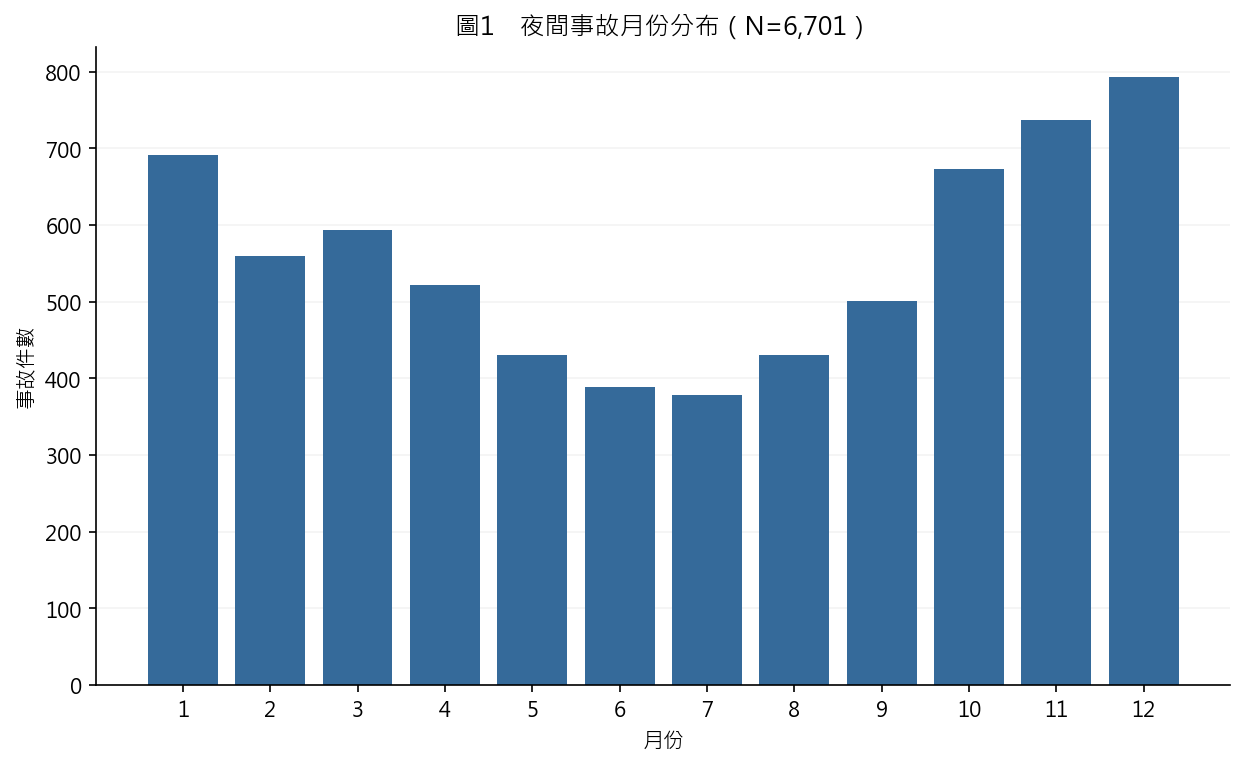

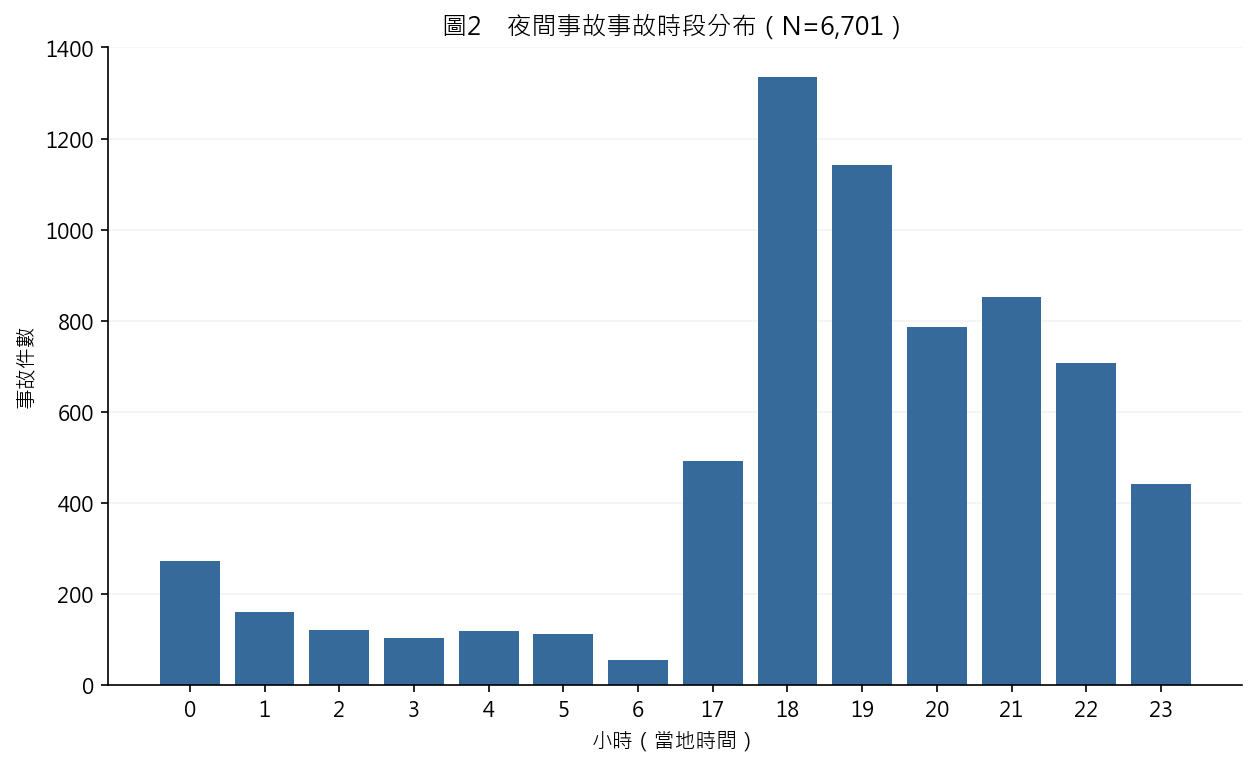

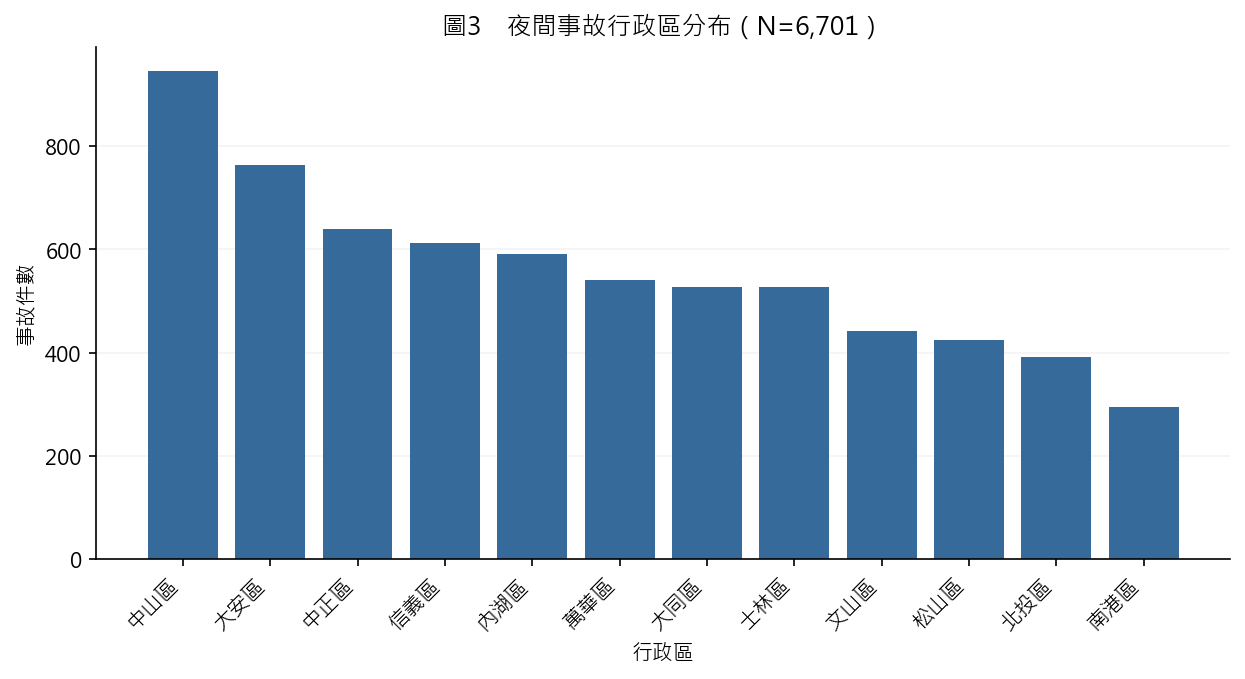

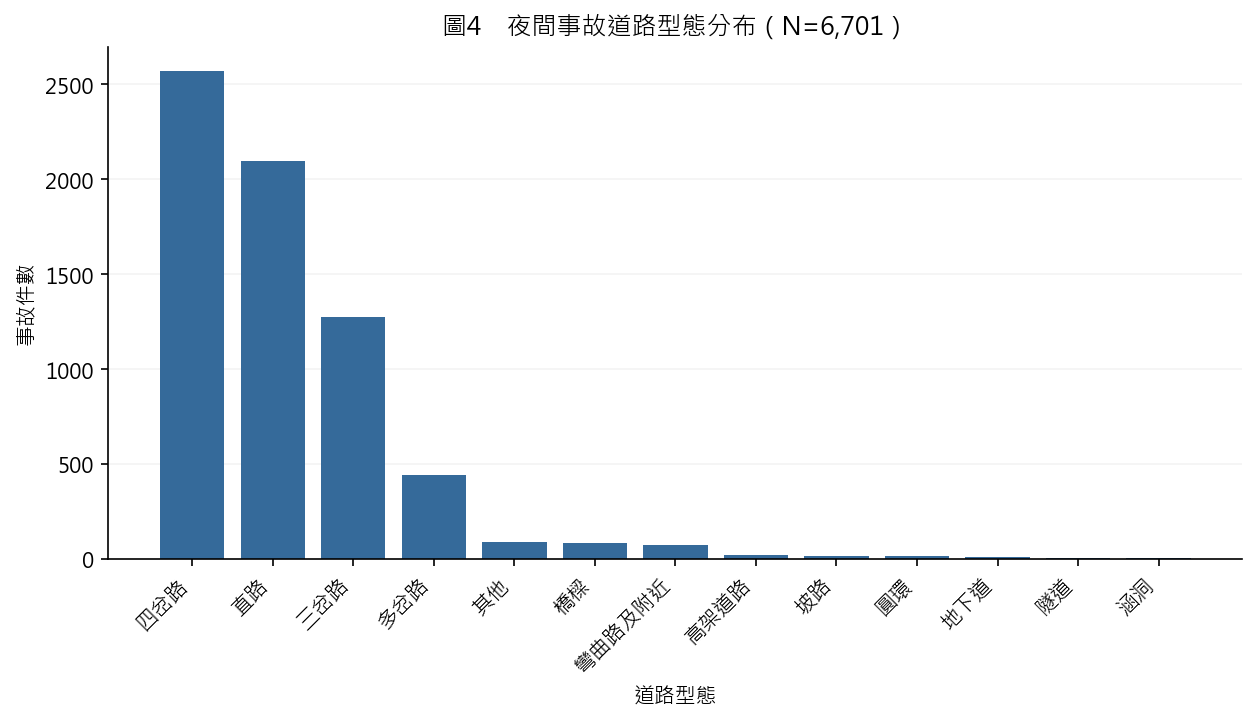

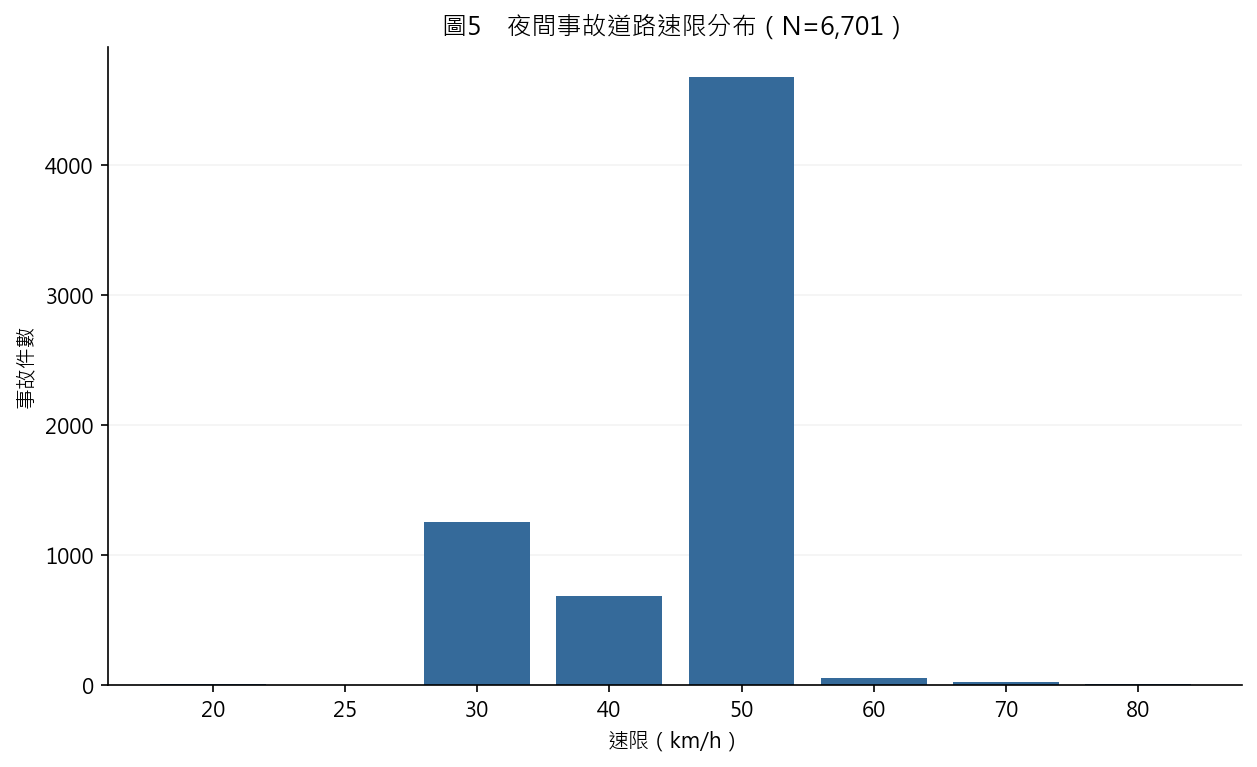

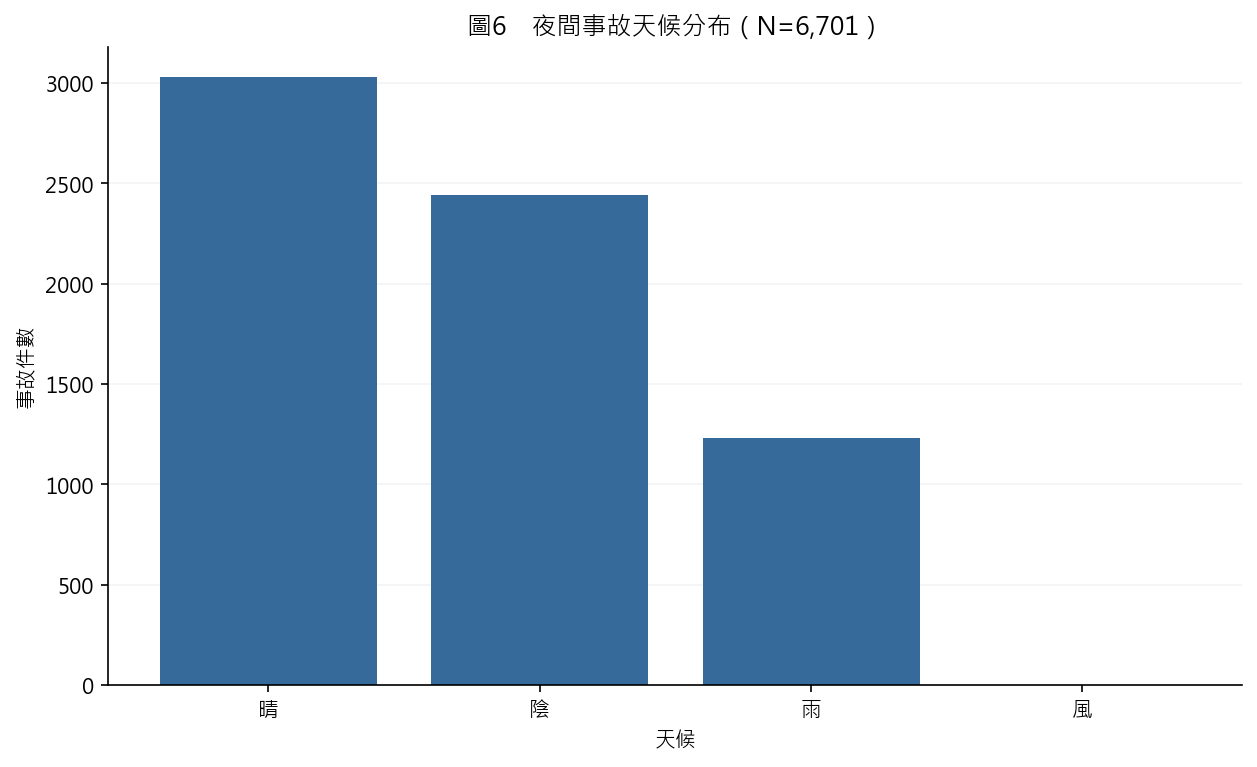

速限是道路限制，非實際車速；分布未調整交通量、道路長度、月份天數或天候暴露時間。


In [4]:
flow = pd.DataFrame([
    ['全年衍生資料', len(descriptive)],
    ['日出日落夜間', int(descriptive.is_night.eq(1).sum())],
    ['排除3筆關鍵道路類別缺失及91筆速限0後', len(analysis)]
], columns=['樣本階段', '件數'])
assert flow.iloc[1, 1] == 6795
print('表3：樣本篩選')
display(flow)

plots = [
    ('month', '月份', '月份', False, 1, 'month'),
    ('hour', '事故時段', '小時（當地時間）', False, 2, 'hour'),
    ('district', '行政區', '行政區', True, 3, 'district'),
    ('road_form_label', '道路型態', '道路型態', True, 4, 'road_form'),
    ('speed_limit', '道路速限', '速限（km/h）', False, 5, 'speed_limit'),
    ('weather_label', '天候', '天候', True, 6, 'weather'),
]
for col, title, xlabel, categorical, number, filename in plots:
    counts = analysis[col].value_counts()
    counts = counts.sort_values(ascending=False) if categorical else counts.sort_index()
    fig, ax = plt.subplots(figsize=(9, 5.6), dpi=150)
    ax.bar([str(x) for x in counts.index], counts.values, color='#356a9a')
    ax.set(title=f'圖{number}　夜間事故{title}分布（N=6,701）',
           xlabel=xlabel, ylabel='事故件數')
    rotation = 45 if categorical and len(counts) > 5 else 0
    ax.tick_params(axis='x', rotation=rotation, labelsize=10)
    if rotation:
        plt.setp(ax.get_xticklabels(), ha='right')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    fig.subplots_adjust(left=.14, right=.98, bottom=.29 if rotation else .14, top=.90)
    fig.savefig(OUT / f'{number:02d}_{filename}.png', dpi=150, bbox_inches='tight', pad_inches=.25)
    plt.show()
    plt.close(fig)

flow.to_csv(OUT / 'sample_flow.csv', index=False, encoding='utf-8-sig')
print('速限是道路限制，非實際車速；分布未調整交通量、道路長度、月份天數或天候暴露時間。')

## 2. PCA、候選群數與敏感度

主規格移除 `z__month_sin`、`z__month_cos`，由49個特徵變成47個。保留原樣本與其餘欄位的編碼、標準化及權重，重新執行完整 PCA，保留累積解釋變異至少80%的最少主成分；PCA scores 不再 whiten 或額外標準化。

比較 K=2–6；主模型 `n_init=50, random_state=5166`。Silhouette固定抽樣3,000件；穩定性為10組固定種子、各 `n_init=10` 的45組兩兩 ARI平均。Ward階層式分群僅用固定1,000件輔助。含月份的基準也在本文件重新執行，避免只依聊天紀錄引用。

表4：PCA比較（每規格 N=6,701）


,矩陣,規格,特徵數,主成分數,累積解釋變異
0,unweighted,含月份,49,7,0.848896
1,unweighted,不含月份,47,6,0.839675
2,block_weighted,含月份,49,4,0.868032
3,block_weighted,不含月份,47,3,0.921299


表5：群數、穩定性及Ward抽樣比較（全樣本 N=6,701；silhouette N=3,000；Ward N=1,000）


,矩陣,規格,K,主成分數,silhouette,CH,DB,穩定性ARI平均,穩定性ARI最小,最小群件數,inertia,Ward抽樣silhouette
0,unweighted,含月份,2,7,0.192675,1674.971532,1.957464,1.000000,1.000000,2944,32333.912893,0.184373
1,unweighted,含月份,3,7,0.194911,1420.256619,1.763346,0.997977,0.991401,1410,28382.080188,0.123625
2,unweighted,含月份,4,7,0.189330,1357.025777,1.629893,0.941476,0.818997,1126,25137.496969,0.134757
3,unweighted,含月份,5,7,0.183495,1306.621552,1.506977,0.994614,0.978154,1071,22700.406989,0.131235
4,unweighted,含月份,6,7,0.196139,1272.084090,1.436332,0.982333,0.925802,596,20727.144964,0.134251
5,unweighted,不含月份,2,6,0.263987,2569.687129,1.545314,1.000000,1.000000,2944,20761.952634,0.243786
6,unweighted,不含月份,3,6,0.282858,2369.110104,1.330951,1.000000,1.000000,1417,16824.380220,0.255052
7,unweighted,不含月份,4,6,0.274291,2283.730283,1.275317,0.989971,0.981196,688,14199.577871,0.226166
8,unweighted,不含月份,5,6,0.269068,2181.719756,1.258083,0.916932,0.706199,571,12471.722342,0.243977
9,unweighted,不含月份,6,6,0.276740,2099.875308,1.279137,0.925988,0.782428,477,11185.118482,0.245136


表6：跨權重設定的一致度（N=6,701）


,規格,K,跨矩陣ARI
0,含月份,2,1.000000
1,含月份,3,0.315800
2,含月份,4,0.775370
3,含月份,5,0.842861
4,含月份,6,0.767710
5,不含月份,2,1.000000
6,不含月份,3,1.000000
7,不含月份,4,0.956202
8,不含月份,5,0.458753
9,不含月份,6,0.523214


表7：各主成分主要loading


,矩陣,規格,主成分,變數,loading,解釋變異比例
0,unweighted,含月份,1,z__hour_cos,0.683691,0.228332
1,unweighted,含月份,1,z__hour_sin,0.626987,0.228332
2,unweighted,含月份,1,z__month_cos,-0.279671,0.228332
3,unweighted,含月份,1,z__month_sin,0.230489,0.228332
4,unweighted,含月份,1,z__speed_limit,-0.057518,0.228332
...,...,...,...,...,...,...
90,block_weighted,不含月份,3,z__hour_sin,0.707236,0.145663
91,block_weighted,不含月份,3,z__hour_cos,-0.705483,0.145663
92,block_weighted,不含月份,3,z__speed_limit,0.036620,0.145663
93,block_weighted,不含月份,3,weather_code__7,-0.020894,0.145663


舊版K=5重現ARI： 1.0


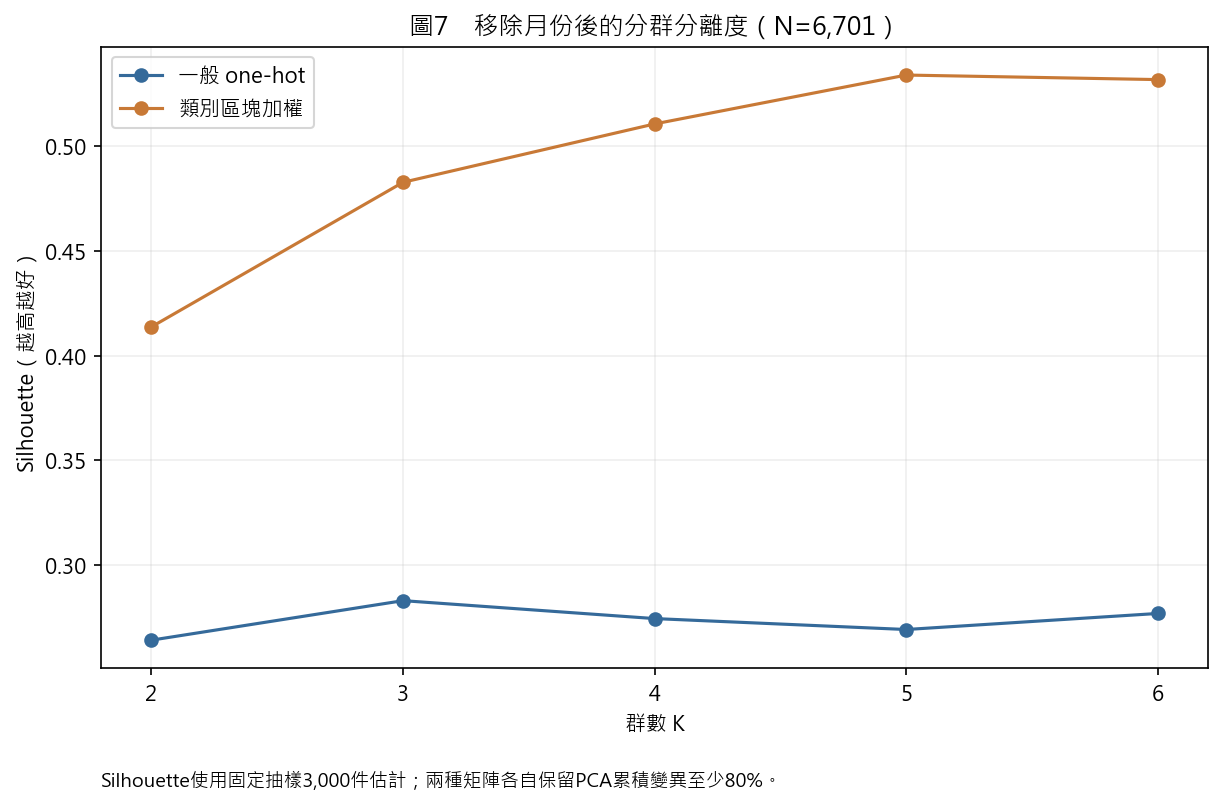

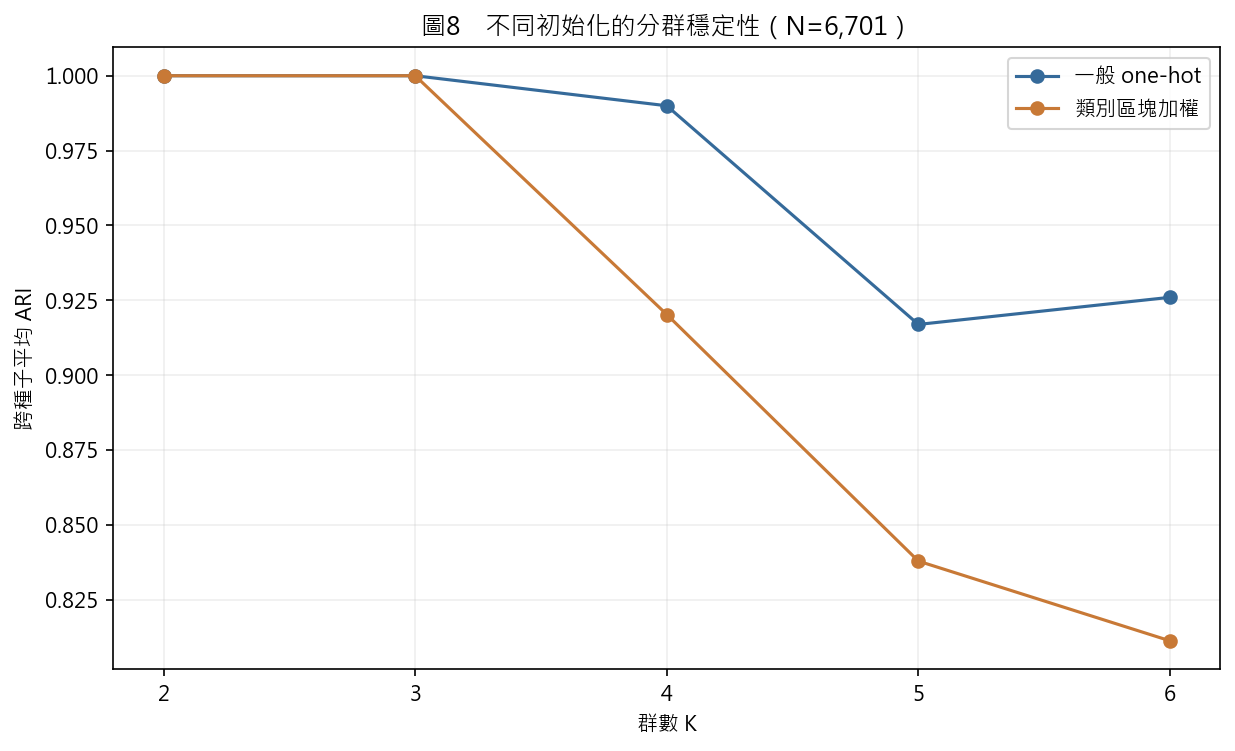

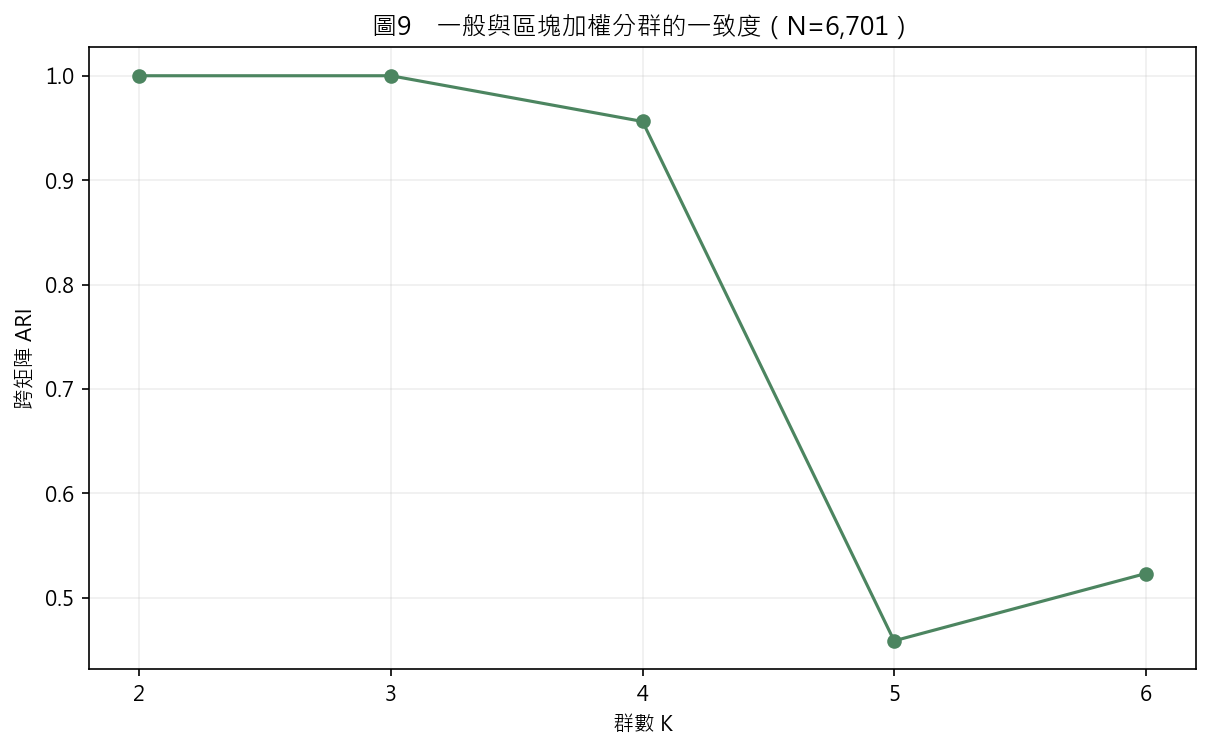

In [5]:
labels = {}
scores80 = {}
pca_rows = []
loading_rows = []
metric_rows = []
hier_idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(analysis), 1000, replace=False))
for variant in ['unweighted', 'block_weighted']:
    for remove_month in [False, True]:
        specification = '不含月份' if remove_month else '含月份'
        drop = ['record_id'] + (['z__month_sin', 'z__month_cos'] if remove_month else [])
        X = frames[variant].drop(columns=drop)
        pca = PCA(svd_solver='full')
        scores = pca.fit_transform(X.to_numpy(dtype=float))
        cum = pca.explained_variance_ratio_.cumsum()
        npc = int(np.searchsorted(cum, .80) + 1)
        z = scores[:, :npc]
        scores80[(variant, specification)] = z
        pca_rows.append({'矩陣': variant, '規格': specification, '特徵數': X.shape[1],
                         '主成分數': npc, '累積解釋變異': cum[npc - 1]})
        for i in range(min(6, npc)):
            for j in np.argsort(np.abs(pca.components_[i]))[::-1][:5]:
                loading_rows.append({'矩陣': variant, '規格': specification, '主成分': i + 1,
                                     '變數': X.columns[j], 'loading': pca.components_[i, j],
                                     '解釋變異比例': pca.explained_variance_ratio_[i]})
        Z = linkage(z[hier_idx], method='ward', optimal_ordering=False)
        for k in range(2, 7):
            km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE, algorithm='lloyd')
            lab = km.fit_predict(z)
            seed_labs = [KMeans(n_clusters=k, n_init=10, random_state=seed, algorithm='lloyd').fit_predict(z)
                         for seed in SEEDS]
            aris = [adjusted_rand_score(a, b) for a, b in itertools.combinations(seed_labs, 2)]
            labels[(variant, specification, k)] = lab
            metric_rows.append({
                '矩陣': variant, '規格': specification, 'K': k, '主成分數': npc,
                'silhouette': silhouette_score(z, lab, sample_size=3000, random_state=RANDOM_STATE),
                'CH': calinski_harabasz_score(z, lab), 'DB': davies_bouldin_score(z, lab),
                '穩定性ARI平均': np.mean(aris), '穩定性ARI最小': min(aris),
                '最小群件數': int(np.bincount(lab).min()), 'inertia': km.inertia_,
                'Ward抽樣silhouette': silhouette_score(z[hier_idx], fcluster(Z, k, criterion='maxclust'))
            })
pca_summary = pd.DataFrame(pca_rows)
loadings = pd.DataFrame(loading_rows)
metrics = pd.DataFrame(metric_rows)
agreement = pd.DataFrame([
    {'規格': spec, 'K': k, '跨矩陣ARI': adjusted_rand_score(
        labels[('unweighted', spec, k)], labels[('block_weighted', spec, k)])}
    for spec in ['含月份', '不含月份'] for k in range(2, 7)])
print('表4：PCA比較（每規格 N=6,701）')
display(pca_summary)
print('表5：群數、穩定性及Ward抽樣比較（全樣本 N=6,701；silhouette N=3,000；Ward N=1,000）')
display(metrics)
print('表6：跨權重設定的一致度（N=6,701）')
display(agreement)
print('表7：各主成分主要loading')
display(loadings)

old = pd.read_csv(ROOT / 'finding/assets/nighttime_cluster_profiles/primary_k5_assignments.csv', encoding='utf-8-sig')
assert old.record_id.tolist() == analysis.record_id.tolist()
reproduction_ari = adjusted_rand_score(old.cluster_id, labels[('unweighted', '含月份', 5)])
assert reproduction_ari == 1.0
print('舊版K=5重現ARI：', reproduction_ari)
for name, table in [('pca_summary', pca_summary), ('loadings', loadings), ('k_comparison', metrics), ('cross_matrix_agreement', agreement)]:
    table.to_csv(OUT / (name + '.csv'), index=False, encoding='utf-8-sig')

metric_plots = [
    (7, 'silhouette', '移除月份後的分群分離度', 'Silhouette（越高越好）', 'silhouette'),
    (8, '穩定性ARI平均', '不同初始化的分群穩定性', '跨種子平均 ARI', 'stability'),
]
for number, metric, title, ylabel, filename in metric_plots:
    fig, ax = plt.subplots(figsize=(9, 5.6), dpi=150)
    for variant, color in [('unweighted', '#356a9a'), ('block_weighted', '#c87936')]:
        part = metrics[(metrics['矩陣'] == variant) & (metrics['規格'] == '不含月份')]
        label = '一般 one-hot' if variant == 'unweighted' else '類別區塊加權'
        ax.plot(part.K, part[metric], marker='o', color=color, label=label)
    ax.set(title=f'圖{number}　{title}（N=6,701）',
           xlabel='群數 K', ylabel=ylabel, xticks=range(2, 7))
    ax.legend(fontsize=10)
    ax.grid(alpha=.2)
    fig.subplots_adjust(left=.16, right=.98, bottom=.16, top=.90)
    if number == 7:
        fig.text(.16, .02, 'Silhouette使用固定抽樣3,000件估計；兩種矩陣各自保留PCA累積變異至少80%。', fontsize=9)
    fig.savefig(OUT / f'{number:02d}_{filename}.png', dpi=150, bbox_inches='tight', pad_inches=.25)
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5.6), dpi=150)
ag = agreement[agreement['規格'] == '不含月份']
ax.plot(ag.K, ag['跨矩陣ARI'], marker='o', color='#4c8560')
ax.set(title='圖9　一般與區塊加權分群的一致度（N=6,701）',
       xlabel='群數 K', ylabel='跨矩陣 ARI', xticks=range(2, 7))
ax.grid(alpha=.2)
fig.subplots_adjust(left=.16, right=.98, bottom=.16, top=.90)
fig.savefig(OUT / '09_weight_agreement.png', dpi=150, bbox_inches='tight', pad_inches=.25)
plt.show()
plt.close(fig)

## 3. 五群情境與分群後結果

群名依輸入特徵的 profile 命名，不使用照明、傷亡或地理結果。所有比例以各群全部事故為分母；傷亡與座標在主樣本沒有缺值。下列名稱與 `random_state=5166` 的標籤對應經特徵檢查，不適用於任意重跑後的標籤編號。

In [6]:
NAMES = {0: '凌晨型', 1: '速限50晚間型', 2: '低速限型', 3: '傍晚直路型', 4: '傍晚交岔路型'}
analysis['cluster_id'] = labels[('unweighted', '不含月份', 5)]
analysis['群組'] = analysis.cluster_id.map(NAMES)
# 防止環境差異造成標籤換序後誤用群名。
assert analysis.groupby('cluster_id').size().tolist() == [571, 1958, 1183, 1135, 1854]
assert analysis.loc[analysis.cluster_id.eq(3), 'road_form_code'].eq(14).mean() > .95
assert analysis.loc[analysis.cluster_id.eq(2), 'speed_limit'].median() == 30

def top(g, col, n=3):
    counts = g[col].value_counts().head(n)
    return '；'.join(f'{value}（{count / len(g) * 100:.1f}%）' for value, count in counts.items())

def wilson(count, n):
    z = norm.ppf(.975)
    p = count / n
    den = 1 + z*z/n
    middle = (p + z*z/(2*n))/den
    delta = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return middle - delta, middle + delta

profile_rows, outcome_rows, district_rows = [], [], []
for cid, g in analysis.groupby('cluster_id'):
    n = len(g)
    profile_rows.append({
        '群組': NAMES[cid], '件數': n, '占比_pct': n / len(analysis) * 100,
        '平均速限': g.speed_limit.mean(), '速限中位數': g.speed_limit.median(),
        '主要小時': top(g, 'hour', 4), '主要月份': top(g, 'month', 4),
        '主要天候': top(g, 'weather_label'), '主要道路型態': top(g, 'road_form_label'),
        '主要事故位置代碼': top(g, 'crash_position_code'),
    })
    issue = int(g.light_code.isin([6, 7]).sum())
    deaths = int(g.fatal24.sum())
    issue_lo, issue_hi = wilson(issue, n)
    fatal_lo, fatal_hi = wilson(deaths, n)
    inj_se = g.injuries.std(ddof=1) / np.sqrt(n)
    outcome_rows.append({
        '群組': NAMES[cid], 'N': n, '有照明且開啟_n': int(g.light_code.eq(5).sum()),
        '照明未開啟故障_n': int(g.light_code.eq(6).sum()), '無照明_n': int(g.light_code.eq(7).sum()),
        '照明未開啟故障_pct': g.light_code.eq(6).mean() * 100,
        '無照明_pct': g.light_code.eq(7).mean() * 100,
        '照明問題_pct': issue / n * 100, '照明問題CI低_pct': issue_lo*100, '照明問題CI高_pct': issue_hi*100,
        '死亡事故_n': deaths, '死亡事故_pct': deaths / n * 100,
        '死亡CI低_pct': fatal_lo*100, '死亡CI高_pct': fatal_hi*100,
        '受傷人數均值': g.injuries.mean(), '受傷人數SD': g.injuries.std(ddof=1),
        '受傷均值CI低': g.injuries.mean() - 1.96*inj_se,
        '受傷均值CI高': g.injuries.mean() + 1.96*inj_se,
        '受傷人數中位數': g.injuries.median(), '2至30日死亡人數': g.deaths_2to30.sum(),
    })
    for district, count in g.district.value_counts().items():
        district_rows.append({'群組': NAMES[cid], '行政區': district, '件數': count, '群組N': n,
                              '群內_pct': count/n*100,
                              '全樣本_pct': analysis.district.eq(district).mean()*100})
profile = pd.DataFrame(profile_rows)
outcome_table = pd.DataFrame(outcome_rows)
district_table = pd.DataFrame(district_rows)
district_table['相對全樣本百分點差'] = district_table['群內_pct'] - district_table['全樣本_pct']
print('表8：五群profile（N=6,701）')
display(profile)
print('表9：照明、死亡及受傷（各列分母為N；CI為95%，比例採Wilson，受傷均值採常態近似）')
display(outcome_table)
print('表10：行政區組成（群內比例，非區內事故率）')
display(district_table)

transitions = pd.crosstab(old.cluster_name, analysis['群組'])
print('表11：含月份與不含月份的一般矩陣K=5交叉件數（N=6,701）')
display(transitions)
for name, table in [('cluster_profile', profile), ('cluster_outcomes', outcome_table), ('cluster_districts', district_table)]:
    table.to_csv(OUT / (name + '.csv'), index=False, encoding='utf-8-sig')
transitions.to_csv(OUT / 'month_no_month_transition.csv', encoding='utf-8-sig')

表8：五群profile（N=6,701）


,群組,件數,占比_pct,平均速限,速限中位數,主要小時,主要月份,主要天候,主要道路型態,主要事故位置代碼
0,凌晨型,571,8.521116,43.134851,50.0,2（20.8%）；4（20.7%）；5（19.8%）；3（18.2%）,1（12.1%）；11（10.2%）；2（10.0%）；12（9.6%）,晴（45.2%）；陰（31.9%）；雨（22.9%）,四岔路（42.2%）；直路（27.0%）；三岔路（16.3%）,1（45.7%）；9（25.7%）；2（17.5%）
1,速限50晚間型,1958,29.219519,49.193054,50.0,21（35.5%）；22（30.3%）；23（18.1%）；0（11.0%）,1（9.4%）；3（9.0%）；12（9.0%）；11（8.6%）,晴（44.5%）；陰（37.4%）；雨（18.0%）,四岔路（38.7%）；直路（31.5%）；三岔路（17.7%）,1（42.8%）；9（28.9%）；2（18.7%）
2,低速限型,1183,17.654081,30.655114,30.0,18（19.7%）；19（19.2%）；20（18.3%）；21（13.2%）,12（11.5%）；1（10.4%）；11（10.4%）；10（10.2%）,晴（45.6%）；陰（36.7%）；雨（17.7%）,四岔路（44.5%）；三岔路（24.9%）；直路（20.8%）,1（57.2%）；9（19.8%）；2（14.3%）
3,傍晚直路型,1135,16.937770,48.775330,50.0,18（38.2%）；19（30.1%）；20（16.9%）；17（14.7%）,12（14.7%）；11（13.5%）；10（11.6%）；1（10.2%）,晴（45.6%）；陰（37.3%）；雨（17.1%）,直路（95.1%）；彎曲路及附近（1.1%）；橋樑（0.8%）,9（84.4%）；7（5.4%）；8（4.5%）
4,傍晚交岔路型,1854,27.667512,49.390507,50.0,18（36.0%）；19（31.0%）；20（20.4%）；17（12.6%）,12（13.9%）；11（12.6%）；1（10.7%）；10（10.7%）,晴（45.4%）；陰（36.1%）；雨（18.4%）,四岔路（56.5%）；三岔路（29.2%）；多岔路（10.6%）,1（62.4%）；2（29.9%）；18（2.4%）


表9：照明、死亡及受傷（各列分母為N；CI為95%，比例採Wilson，受傷均值採常態近似）


,群組,N,有照明且開啟_n,照明未開啟故障_n,無照明_n,照明未開啟故障_pct,無照明_pct,照明問題_pct,照明問題CI低_pct,照明問題CI高_pct,死亡事故_n,死亡事故_pct,死亡CI低_pct,死亡CI高_pct,受傷人數均值,受傷人數SD,受傷均值CI低,受傷均值CI高,受傷人數中位數,2至30日死亡人數
0,凌晨型,571,497,53,21,9.281961,3.677758,12.959720,10.450545,15.963949,11,1.926445,1.079037,3.416369,1.308231,0.600805,1.258951,1.357511,1.0,0.0
1,速限50晚間型,1958,1851,90,17,4.596527,0.868233,5.464760,4.542421,6.561507,10,0.510725,0.277654,0.937606,1.365679,0.616654,1.338365,1.392994,1.0,2.0
2,低速限型,1183,1101,64,18,5.409975,1.521555,6.931530,5.619223,8.522638,3,0.253593,0.086281,0.742933,1.350803,0.568056,1.318432,1.383174,1.0,0.0
3,傍晚直路型,1135,1051,68,16,5.991189,1.409692,7.400881,6.017385,9.071761,1,0.088106,0.015555,0.497375,1.375330,0.841028,1.326401,1.424260,1.0,0.0
4,傍晚交岔路型,1854,1746,83,25,4.476807,1.348436,5.825243,4.847628,6.985538,1,0.053937,0.009522,0.304900,1.336570,0.576562,1.310325,1.362815,1.0,0.0


表10：行政區組成（群內比例，非區內事故率）


,群組,行政區,件數,群組N,群內_pct,全樣本_pct,相對全樣本百分點差
0,凌晨型,萬華區,84,571,14.711033,8.058499,6.652535
1,凌晨型,中山區,80,571,14.010508,14.102373,-0.091865
2,凌晨型,大同區,58,571,10.157618,7.864498,2.293120
3,凌晨型,大安區,58,571,10.157618,11.401283,-1.243665
4,凌晨型,信義區,56,571,9.807356,9.147888,0.659467
5,凌晨型,士林區,53,571,9.281961,7.864498,1.417464
6,凌晨型,中正區,39,571,6.830123,9.550813,-2.720691
7,凌晨型,內湖區,35,571,6.129597,8.834502,-2.704905
8,凌晨型,北投區,33,571,5.779335,5.849873,-0.070539
9,凌晨型,松山區,32,571,5.604203,6.327414,-0.723211


表11：含月份與不含月份的一般矩陣K=5交叉件數（N=6,701）


群組,低速限型,傍晚交岔路型,傍晚直路型,凌晨型,速限50晚間型
cluster_name,,,,,
低速限晚間型,1062,0,0,0,9
夏季晚間50型,23,321,194,0,708
春季晚間50型,34,592,335,0,573
深夜凌晨型,51,0,0,571,564
秋冬傍晚50型,13,941,606,0,104


表12：探索性整體比較；未做多重比較校正，未調整群聚相關與混淆


,矩陣,比較變數,卡方,p值,自由度,CramersV,最小期望次數,統計量,epsilon_squared,模擬次數,死亡事故總數
0,unweighted,light_code,49.406286,5.313581e-08,8.0,0.060716,8.265483,NaN,NaN,NaN,NaN
1,unweighted,district,214.144920,3.217578e-24,44.0,0.089383,25.137293,NaN,NaN,NaN,NaN
2,unweighted,受傷人數Kruskal-Wallis,NaN,2.999633e-01,NaN,NaN,NaN,4.878778,0.000131,NaN,NaN
3,unweighted,死亡事故條件Monte Carlo,NaN,2.000000e-05,NaN,NaN,NaN,44.277055,NaN,49999.0,26.0
4,block_weighted,light_code,50.487318,3.293636e-08,8.0,0.061377,7.874646,NaN,NaN,NaN,NaN
5,block_weighted,district,213.684730,3.873110e-24,44.0,0.089287,23.948664,NaN,NaN,NaN,NaN
6,block_weighted,受傷人數Kruskal-Wallis,NaN,5.935817e-02,NaN,NaN,NaN,9.070627,0.000757,NaN,NaN
7,block_weighted,死亡事故條件Monte Carlo,NaN,6.000000e-05,NaN,NaN,NaN,31.525428,NaN,49999.0,26.0


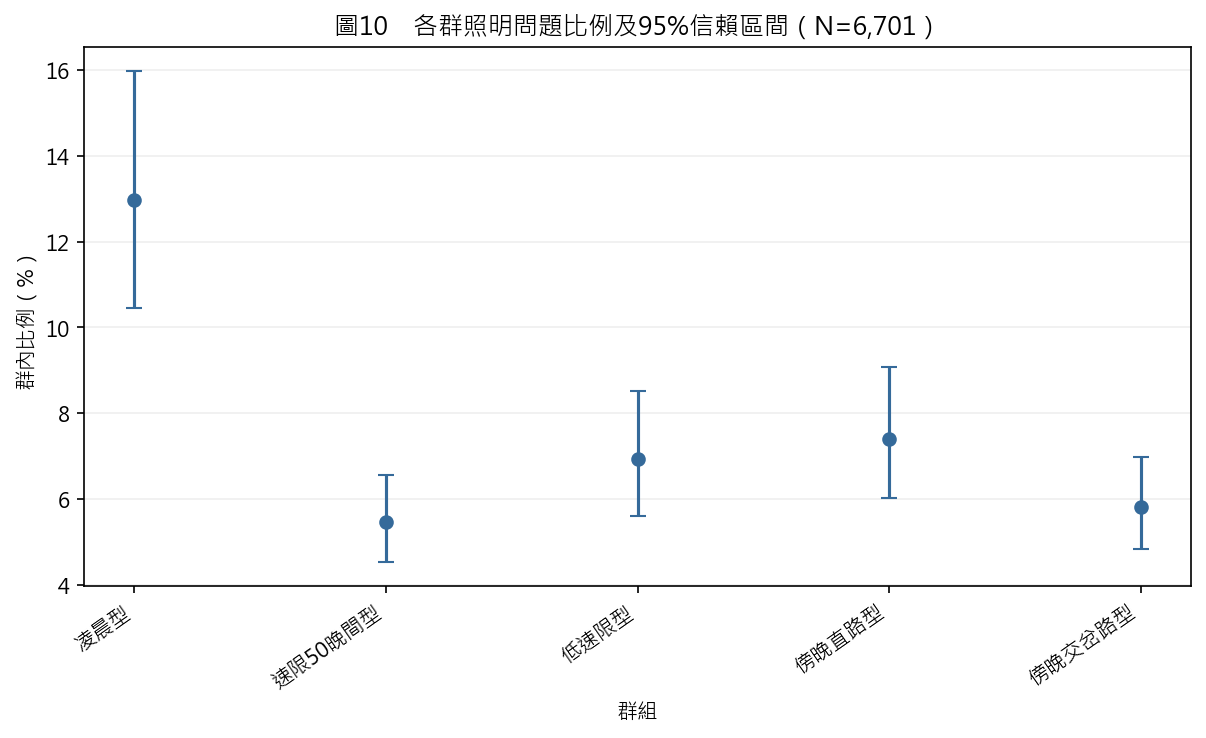

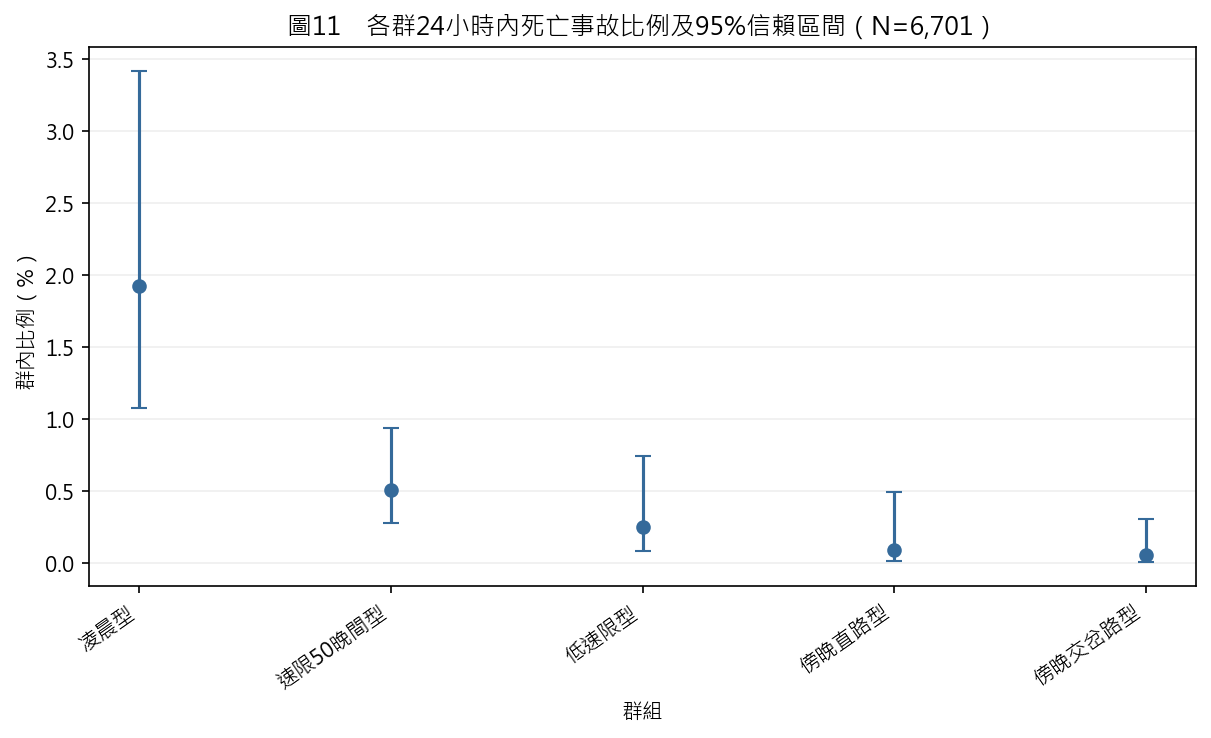

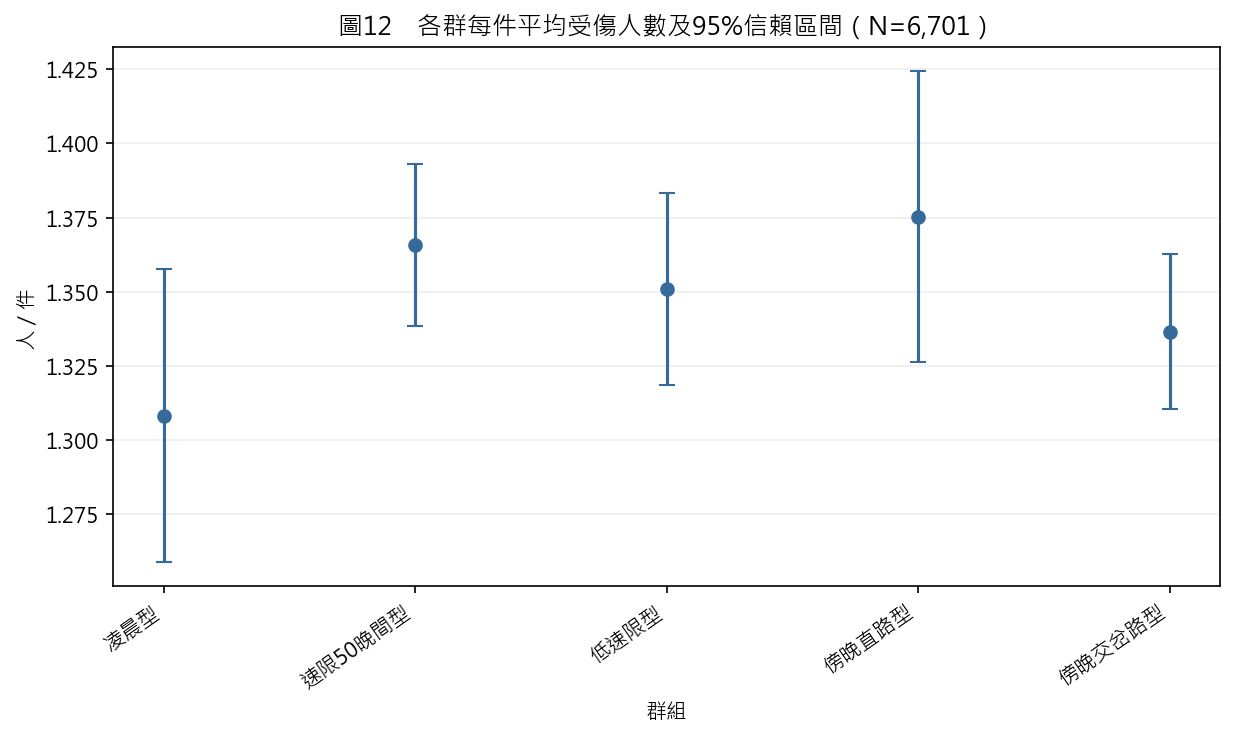

照明問題＝未開啟／故障或無照明；受傷人數不是傷勢嚴重程度。群組內比例不能視為道路事故率。


In [7]:
def categorical_test(group, variable):
    tab = pd.crosstab(group, variable)
    chi2, p, dof, expected = chi2_contingency(tab)
    return {'卡方': chi2, 'p值': p, '自由度': dof,
            'CramersV': np.sqrt(chi2/(tab.to_numpy().sum()*min(tab.shape[0]-1, tab.shape[1]-1))),
            '最小期望次數': expected.min()}

tests = []
for variant in ['unweighted', 'block_weighted']:
    lab = labels[(variant, '不含月份', 5)]
    for col in ['light_code', 'district']:
        tests.append({'矩陣': variant, '比較變數': col, **categorical_test(lab, analysis[col])})
    groups = [analysis.loc[lab == i, 'injuries'].to_numpy() for i in range(5)]
    H, p = kruskal(*groups)
    tests.append({'矩陣': variant, '比較變數': '受傷人數Kruskal-Wallis', '統計量': H,
                  'p值': p, 'epsilon_squared': max(0, (H-4)/(len(analysis)-5))})
    # 死亡事件僅26件，使用固定群大小與死亡總數的條件Monte Carlo檢定。
    sizes = np.bincount(lab)
    events = np.bincount(lab, weights=analysis.fatal24).astype(int)
    total = int(events.sum())
    expected = sizes * (total / sizes.sum())
    def statistic(ev):
        return np.sum((ev-expected)**2/expected +
                      ((sizes-ev)-(sizes-expected))**2/(sizes-expected), axis=-1)
    observed = statistic(events)
    simulated = np.random.default_rng(RANDOM_STATE).multivariate_hypergeometric(sizes, total, size=49999)
    mc_p = (np.count_nonzero(statistic(simulated) >= observed - 1e-10) + 1) / 50000
    tests.append({'矩陣': variant, '比較變數': '死亡事故條件Monte Carlo', '統計量': observed,
                  'p值': mc_p, '模擬次數': 49999, '死亡事故總數': total})
test_table = pd.DataFrame(tests)
print('表12：探索性整體比較；未做多重比較校正，未調整群聚相關與混淆')
display(test_table)
test_table.to_csv(OUT / 'outcome_tests.csv', index=False, encoding='utf-8-sig')

specs = [
    (10, '照明問題_pct', '照明問題CI低_pct', '照明問題CI高_pct', '各群照明問題比例', '群內比例（%）', 'lighting'),
    (11, '死亡事故_pct', '死亡CI低_pct', '死亡CI高_pct', '各群24小時內死亡事故比例', '群內比例（%）', 'fatalities'),
    (12, '受傷人數均值', '受傷均值CI低', '受傷均值CI高', '各群每件平均受傷人數', '人／件', 'injuries'),
]
for number, value, low, high, title, ylabel, filename in specs:
    fig, ax = plt.subplots(figsize=(9, 5.8), dpi=150)
    y = outcome_table[value].to_numpy()
    err = np.vstack([y - outcome_table[low], outcome_table[high] - y])
    ax.errorbar(np.arange(5), y, yerr=err, fmt='o', capsize=4, color='#356a9a')
    ax.set(title=f'圖{number}　{title}及95%信賴區間（N=6,701）',
           ylabel=ylabel, xlabel='群組', xticks=np.arange(5), xticklabels=outcome_table['群組'])
    ax.tick_params(axis='x', rotation=35, labelsize=10)
    plt.setp(ax.get_xticklabels(), ha='right')
    ax.grid(axis='y', alpha=.2)
    fig.subplots_adjust(left=.16, right=.98, bottom=.28, top=.90)
    fig.savefig(OUT / f'{number:02d}_{filename}.png', dpi=150, bbox_inches='tight', pad_inches=.25)
    plt.show()
    plt.close(fig)
print('照明問題＝未開啟／故障或無照明；受傷人數不是傷勢嚴重程度。群組內比例不能視為道路事故率。')

## 4. 地理描述

行政區組成已實際比較。以下另以相同經緯度範圍、點大小與透明度呈現各群事故點位，作探索性座標散點圖；沒有街道底圖，不是空間熱點檢定。所有圖均包含同一主樣本的範圍，不能因小群點少就解讀為道路較安全。

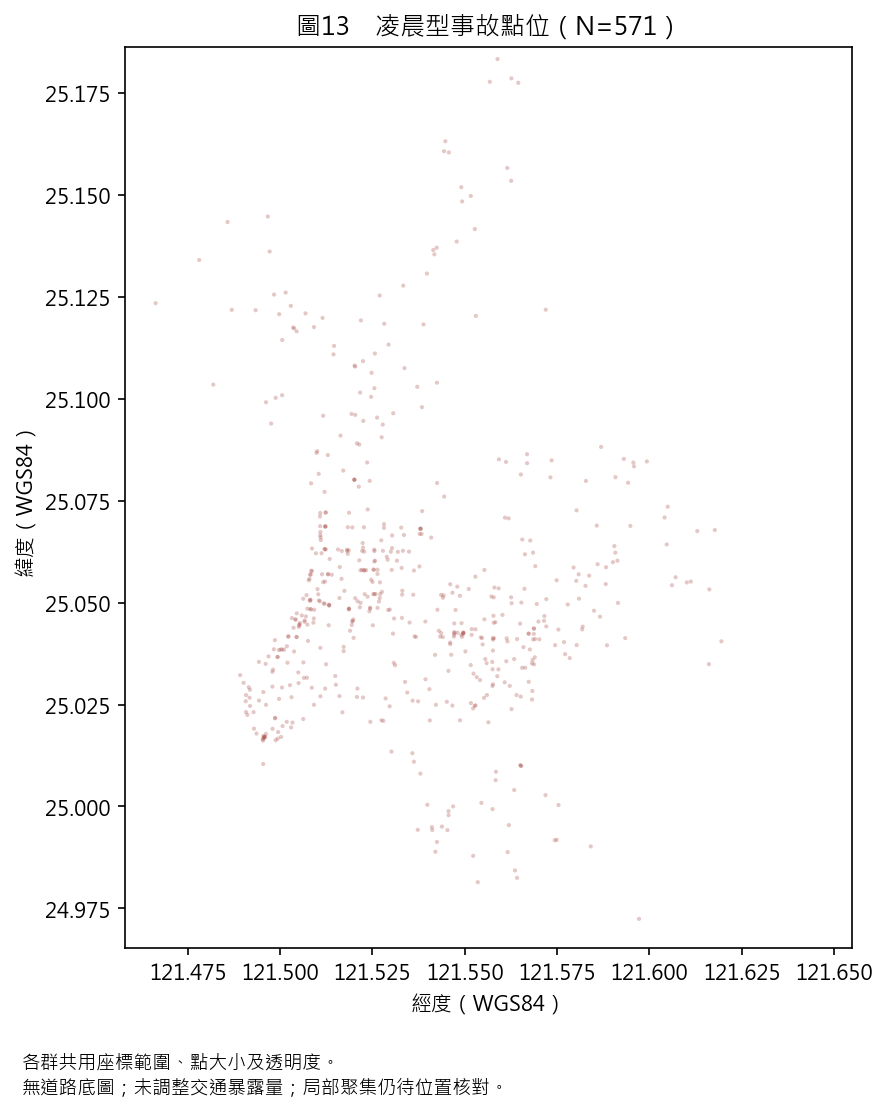

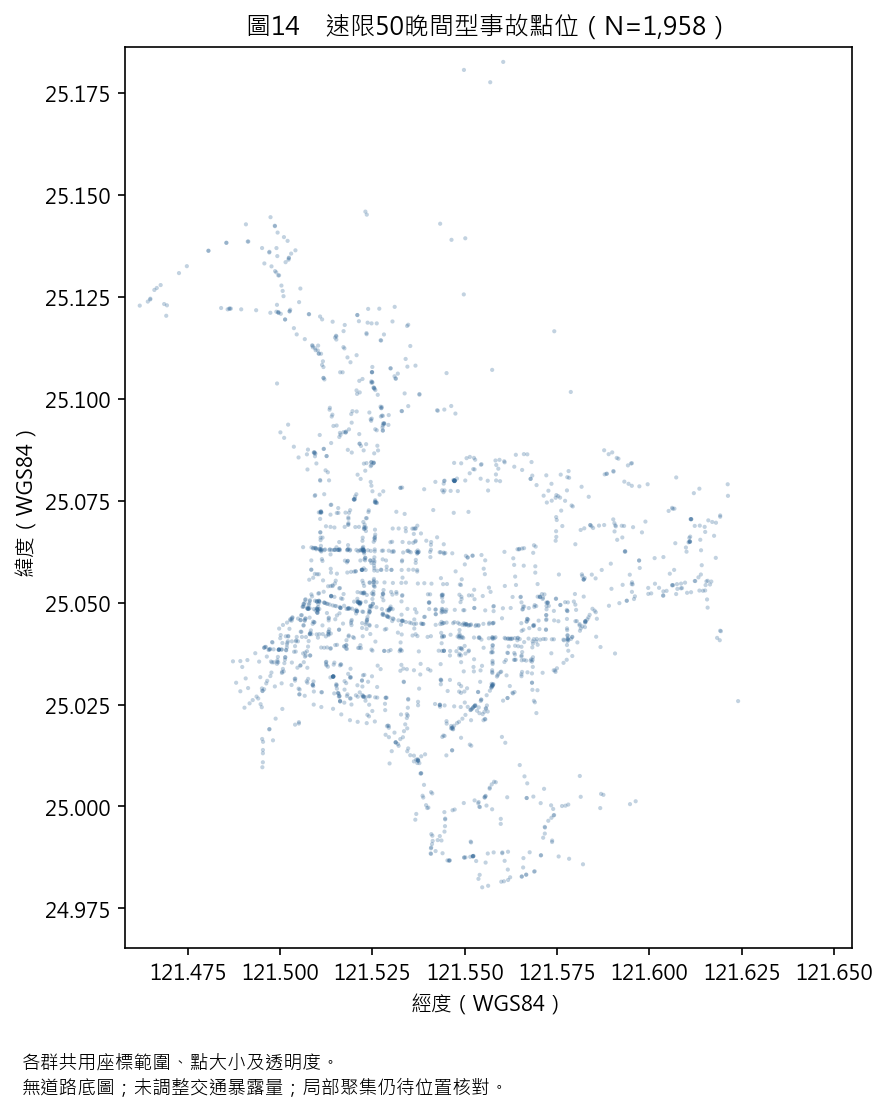

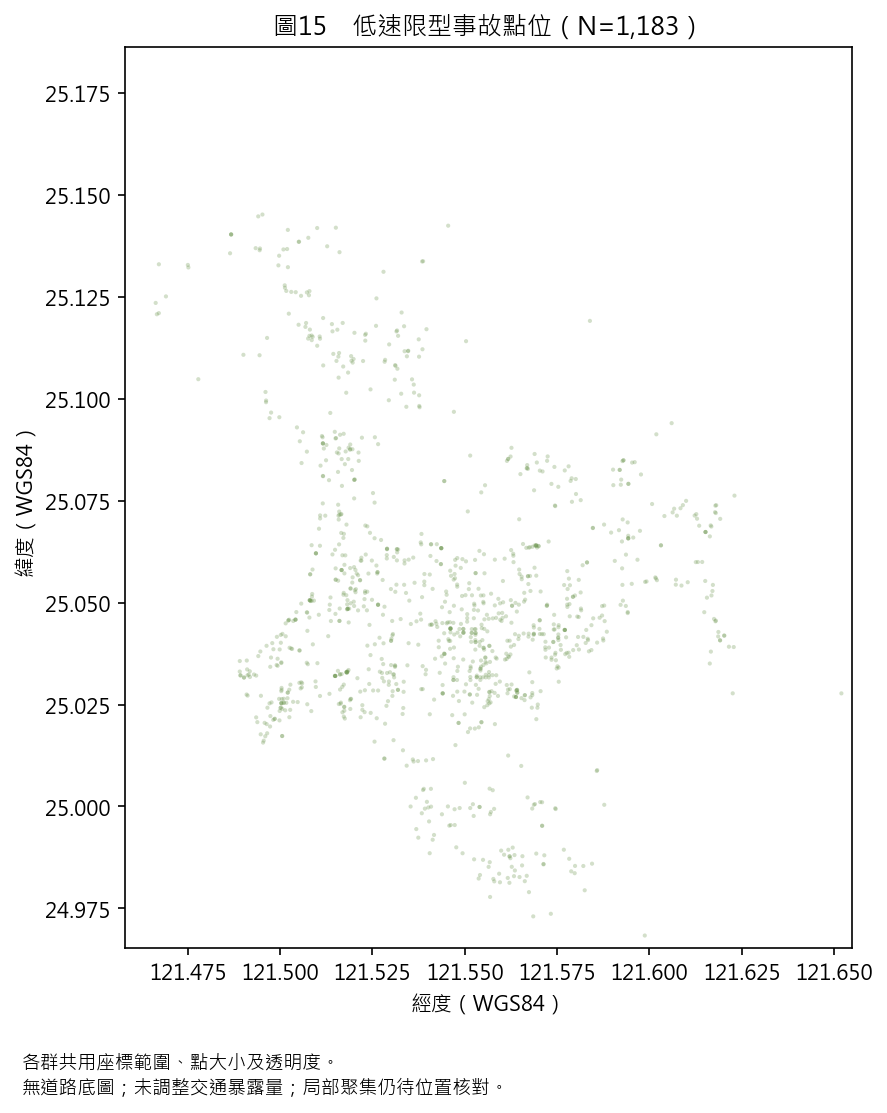

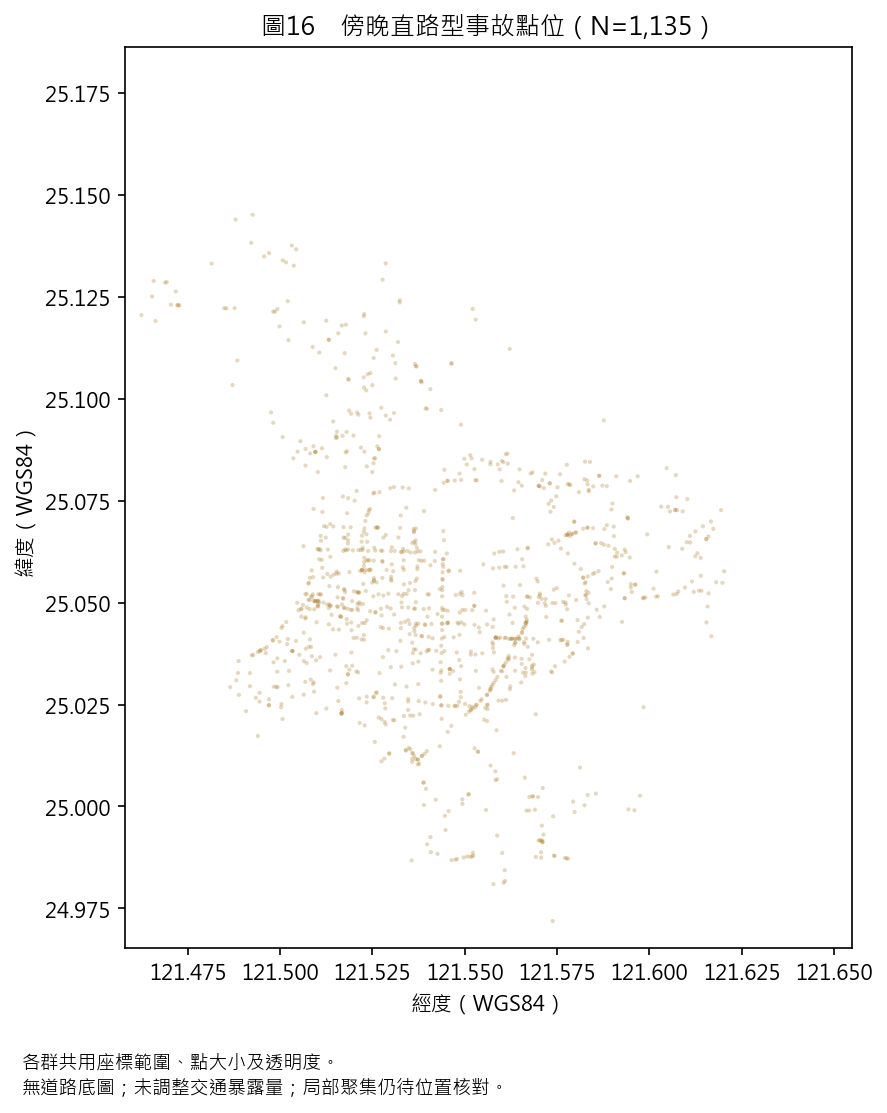

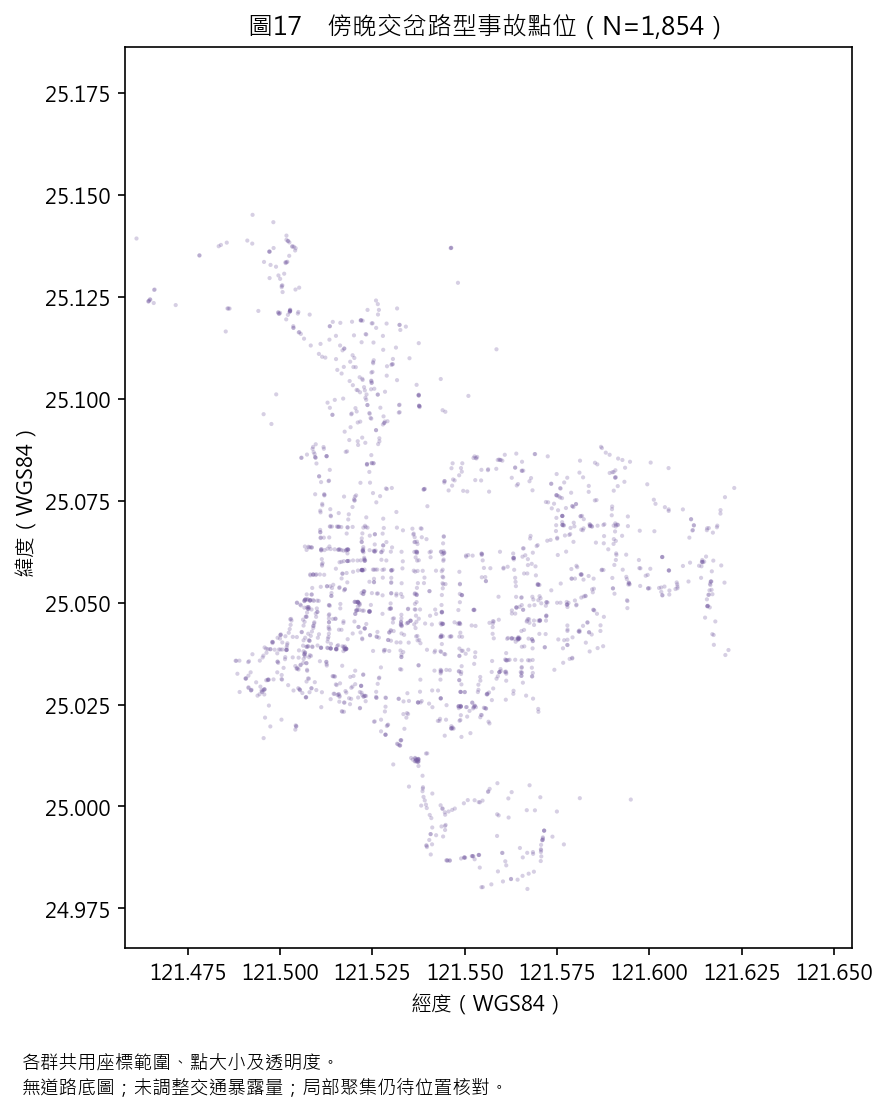

各群平均座標中心最大相距（近似km）： 0.958794457065511
平均中心接近不能排除局部道路聚集；行政區差異也不能替代道路層級熱點檢查。


In [8]:
colors = ['#a64b45', '#356a9a', '#6e9751', '#ae7f2d', '#7960a5']
location_files = ['early_morning', 'evening50', 'low_speed', 'straight', 'intersection']
xlim = (analysis.lon.min() - .003, analysis.lon.max() + .003)
ylim = (analysis.lat.min() - .003, analysis.lat.max() + .003)
for cid, (color, filename) in enumerate(zip(colors, location_files)):
    number = 13 + cid
    g = analysis[analysis.cluster_id.eq(cid)]
    fig, ax = plt.subplots(figsize=(7, 7.8), dpi=150)
    ax.scatter(g.lon, g.lat, s=4, alpha=.30, color=color, edgecolors='none', rasterized=True)
    ax.set(title=f'圖{number}　{NAMES[cid]}事故點位（N={len(g):,}）',
           xlabel='經度（WGS84）', ylabel='緯度（WGS84）', xlim=xlim, ylim=ylim)
    ax.set_aspect(1 / np.cos(np.radians(analysis.lat.mean())))
    ax.ticklabel_format(useOffset=False, axis='both')
    ax.tick_params(labelsize=10)
    fig.subplots_adjust(left=.16, right=.97, bottom=.15, top=.92)
    fig.text(.12, .025, '各群共用座標範圍、點大小及透明度。\n無道路底圖；未調整交通暴露量；局部聚集仍待位置核對。',
             fontsize=9, linespacing=1.5)
    fig.savefig(OUT / f'{number:02d}_location_{filename}.png', dpi=150, bbox_inches='tight', pad_inches=.25)
    plt.show()
    plt.close(fig)

# 對臺北市範圍用局部平面近似計算群中心間距，僅供描述。
xy = np.column_stack([np.radians(analysis.lon)*6371*np.cos(np.radians(analysis.lat.mean())),
                      np.radians(analysis.lat)*6371])
centers = np.array([xy[analysis.cluster_id.eq(i)].mean(axis=0) for i in range(5)])
max_distance = np.sqrt(((centers[:, None] - centers[None, :])**2).sum(axis=-1)).max()
print('各群平均座標中心最大相距（近似km）：', max_distance)
print('平均中心接近不能排除局部道路聚集；行政區差異也不能替代道路層級熱點檢查。')

## 5. 結果解讀、限制及後續

本文件於2026-11-09從乾淨Python kernel依序執行完成，保留實際表格與17張圖；結果已核對並整理至[期中報告](../report/taipei-nighttime-crash-midterm.md)。一般矩陣K=5的群數細分有道路情境意義，但不同初始化的最小兩兩ARI僅0.706，跨權重ARI為0.459，因此不能宣稱五群已最優或穩健。三群可作穩定基準，四群也值得對照。

凌晨型的照明問題12.96%、死亡事故比例1.93%較突出，但整體照明關聯僅V=0.061，行政區關聯V=0.089。各群平均受傷人數接近且中位數皆1，Kruskal–Wallis p=.300；受傷總數不能代表傷勢程度。2至30日死亡共2人，未併入24小時死亡事故指標。

群數選擇綜合分離度、初始化穩定性、跨矩陣一致度及可解釋性，不使用照明或死亡比例來挑選K。所有檢定均為探索性，未做多重比較校正或調整時間／地點群聚相關。信賴區間以固定分群標籤計算，未納入模型選擇及重新分群的不確定性。死亡事件稀少，只描述事故案件內的差異，不估計照明效果或全市道路風險。

已產生同尺度獨立點位圖，沒有道路底圖，未作空間聚集檢定；平均中心接近不能排除局部道路聚集。仍待執行：移除天候、70%／90% PCA門檻、不降維、速限0、固定夜間樣本下的分群敏感度；K=3/4/5的系統性profile與結果對照；道路層級位置核對與分層交叉分析。上述項目不能列為已完成。


In [9]:
# 本Notebook產物檢查；原始資料與既有處理資料只讀。
assert outcome_table.N.sum() == 6701
assert outcome_table['死亡事故_n'].sum() == 26
assert outcome_table['照明未開啟故障_n'].sum() == 358
assert outcome_table['無照明_n'].sum() == 97
assert agreement.loc[(agreement['規格'] == '不含月份') & agreement.K.eq(3), '跨矩陣ARI'].iloc[0] == 1.0
print('所有實際樣本、總數及基準重現檢查通過。')
print('輸出圖表：', [p.name for p in sorted(OUT.glob('*.png'))])
print('執行狀態：乾淨kernel依序執行成功；本地檔案待學生檢閱後自行commit/push。')

所有實際樣本、總數及基準重現檢查通過。
輸出圖表： ['01_month.png', '01a_month.png', '01b_hour.png', '01c_district.png', '01d_road_form.png', '01e_speed_limit.png', '01f_weather.png', '02_hour.png', '02_k_comparison.png', '03_district.png', '03_outcomes.png', '04_locations.png', '04_road_form.png', '05_speed_limit.png', '06_weather.png', '07_silhouette.png', '08_stability.png', '09_weight_agreement.png', '10_lighting.png', '11_fatalities.png', '12_injuries.png', '13_location_early_morning.png', '14_location_evening50.png', '15_location_low_speed.png', '16_location_straight.png', '17_location_intersection.png']
執行狀態：乾淨kernel依序執行成功；本地檔案待學生檢閱後自行commit/push。
